In [1]:
# Importing the libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

In [2]:
# Importing Dataset
# FOR ONLY GOOGLE COLAB

# from google.colab import drive

# drive.mount("/content/drive")

# data_way = "/content/drive/MyDrive/TechIstanbul/ogrenci_calisma_notlari.csv"

# data = pd.read_csv(data_way)

In [3]:
# Importing Dataset
# FOR IDE

data = pd.read_csv("ogrenci_calisma_notlari.csv")

In [4]:
#  Control the data
print(data.head(10))
print(data.describe())

   calisma_saati  sinav_notu
0            0.6          29
1            0.7          33
2            0.8          29
3            0.9          36
4            1.0          22
5            1.0          31
6            1.1          39
7            1.2          31
8            1.2          34
9            1.3          32
       calisma_saati  sinav_notu
count     100.000000  100.000000
mean        5.439000   55.710000
std         3.123805   19.482339
min         0.600000   22.000000
25%         2.550000   39.000000
50%         5.400000   52.500000
75%         8.200000   73.000000
max        10.900000   95.000000


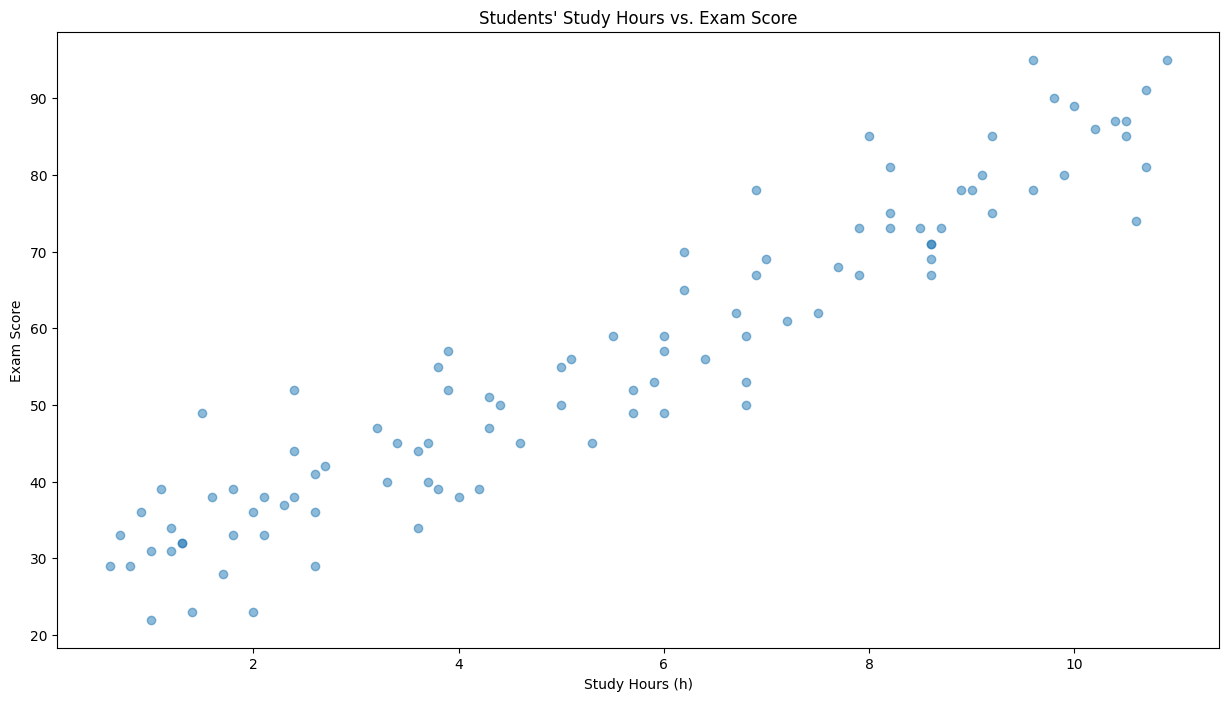

In [5]:
# Data Virtualization
plt.figure(figsize=(15, 8))
plt.scatter(data["calisma_saati"], data["sinav_notu"], alpha=0.5)
plt.xlabel("Study Hours (h)")
plt.ylabel("Exam Score")
plt.title("Students' Study Hours vs. Exam Score")
plt.show()

In [6]:
# Data Splitting
X = data[["calisma_saati"]]
y = data["sinav_notu"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [7]:
# Model Training
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[5.94]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['calisma_saati']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,23.66
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [8]:
# Model Prediction
y_pred = model.predict(X_test)

In [9]:
# Coefficients of Model
print(f"Coefficient of Equality: {round(model.coef_[0], 3)}")

Coefficient of Equality: 5.941


In [10]:
print(f"Intercept: {round(model.intercept_, 3)}")

Intercept: 23.656


In [11]:
print(f"R-squared: {round(model.score(X_test, y_test), 3)}")

R-squared: 0.891


In [12]:
mse = round(mean_squared_error(y_test, y_pred), 3)
print(f"Mean Squared Error: {mse}")

Mean Squared Error: 34.942


In [13]:
print(f"RMSE: {round(np.sqrt(mse), 3)}")

RMSE: 5.911


In [14]:
print(f"MAE: {round(np.mean(np.abs(y_test - y_pred)), 3)}")

MAE: 4.189


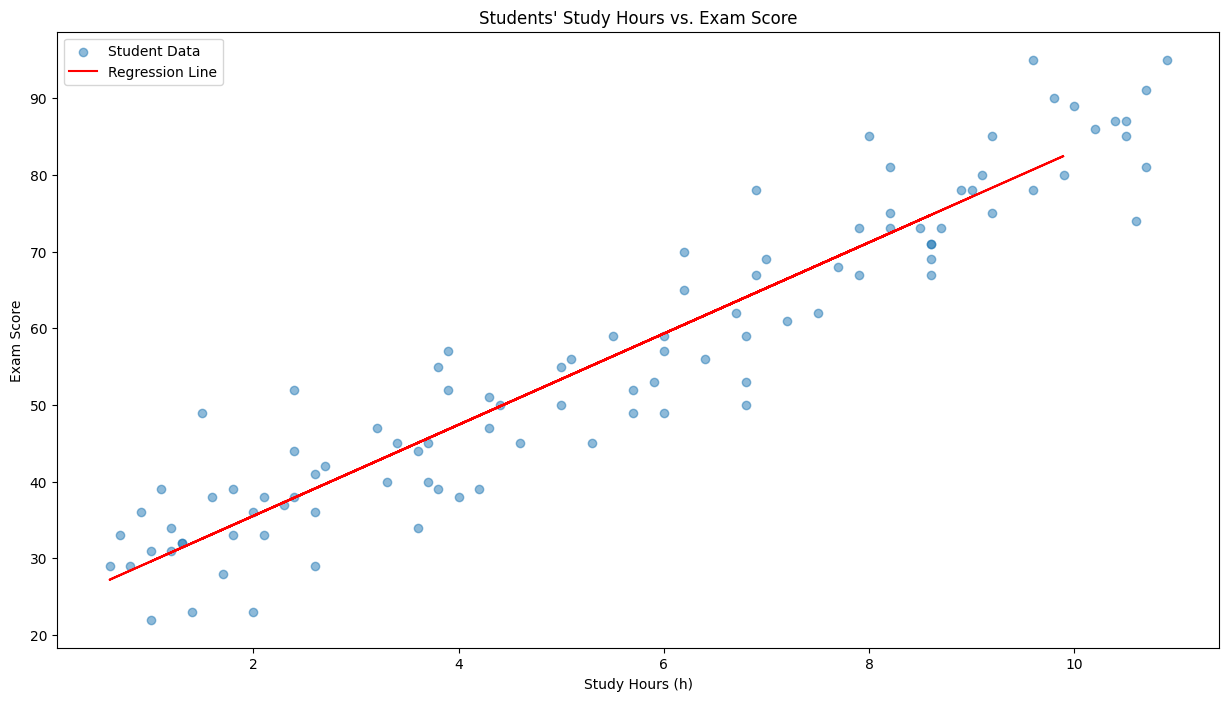

In [15]:
#  Plotting the results
plt.figure(figsize=(15, 8))
plt.scatter(X, y, alpha=0.5)
plt.plot(X_test, y_pred, color="red")
plt.xlabel("Study Hours (h)")
plt.ylabel("Exam Score")
plt.title("Students' Study Hours vs. Exam Score")
plt.legend(["Student Data", "Regression Line"])
plt.show()